# 04 | Hugging Face実画像でMobileNetV3-Smallを転移学習

**対象**：`Programmer-RD-AI/road-issues-detection-dataset`（道路インフラの問題7カテゴリ）。

- Google Colabの**GPUランタイム**を選択し上から実行してください。
- Hugging Faceの認証は**Colab Secrets の `HFH_READ`（read権限）**から取得します。公開データなので未登録でも可能です。
- *正常画像・重症度のラベルはありません*。正解は「問題種別」であり、リスクスコアは後段で明示する**ルールベースの仮定**です。
- **Genesisカメラ画像で学習したモデルではありません**。独立した実画像学習と3Dロボット物理制御を組み合わせます。
- 出力の`road_ml_assets.zip`をNotebook 06に渡します。APIトークンはZIPに入れません。

In [9]:
%pip -q install "datasets>=3,<5" "huggingface_hub>=0.27,<2" "scikit-learn>=1.3,<2" "pandas>=2,<3" "matplotlib>=3.7,<4" "pillow>=10" "scipy>=1.11,<2"
import torch
import torchvision
import sys
print('Python', sys.version.split()[0],'PyTorch', torch.__version__,'Torchvision', torchvision.__version__)
print('CUDA enabled', torch.cuda.is_available())

Python 3.13.15 PyTorch 2.11.0+cu130 Torchvision 0.26.0+cu130
CUDA enabled True


In [10]:
%%writefile road_ml.py
"""Road issue classification utilities for the PAI final project.

The Hugging Face road issues data has *issue category* labels, not defect
severity or normal-vs-abnormal labels. The curated risk score below is a
policy assumption (not learned severity, not a calibrated probability).
"""
from __future__ import annotations
import json
from pathlib import Path
import numpy as np

REPO_ID = 'Programmer-RD-AI/road-issues-detection-dataset'
RISK_BY_LABEL = {
    'Pothole Issues': 0.95,
    'Damaged Road issues': 0.75,
    'Broken Road Sign Issues': 0.70,
    'Illegal Parking Issues': 0.55,
    'Mixed Issues': 0.85,
    'Littering Garbage on Public Places Issues': 0.40,
    'Vandalism Issues': 0.35,
}


def label_risk(label: str) -> float:
    if label not in RISK_BY_LABEL:
        raise ValueError(f'Unknown dataset label: {label!r}. Revisit the risk policy mapping.')
    return float(RISK_BY_LABEL[label])


def expected_policy_risk(class_probabilities, class_names):
    """Expected *heuristic* risk: not probability of a severe physical hazard."""
    vals = np.asarray([label_risk(str(n)) for n in class_names], dtype = float)
    p = np.asarray(class_probabilities, dtype = float)
    if p.shape[-1] != len(vals):
        raise ValueError('class dimension mismatch')
    return np.sum(p*vals, axis = -1)


def select_station(current_xy, locations, scores, visited = None, policy = 'adaptive'):
    """Distance vs learned-category-dependent policy comparison.

    Note: straight-line distance is for target priority only, not obstacle-safe
    path length. The physical controller independently uses A*.
    """
    visited = set(visited or ())
    available = [s for s in locations if s not in visited]
    if not available:
        return None
    pos = np.asarray(current_xy, dtype = float)
    dd = {k:float(np.linalg.norm(pos-np.asarray(locations[k]))) for k in available}
    if policy == 'nearest':
        return min(available, key = lambda k:(dd[k], k))
    if policy != 'adaptive':
        raise ValueError('policy should be nearest or adaptive')
    return max(available, key = lambda k:(3.5*float(scores[k]) - 0.30*dd[k], -dd[k]))


def safe_speed_limit(risk, nominal_mps = 0.65):
    """Interpretable, deliberately conservative safety shield (simulation only)."""
    risk = float(np.clip(risk, 0., 1.))
    if risk >= 0.80:
        return min(nominal_mps, 0.20)
    if risk >= 0.60:
        return min(nominal_mps, 0.32)
    if risk >= 0.40:
        return min(nominal_mps, 0.48)
    return float(nominal_mps)


def save_station_manifest(items, path):
    Path(path).write_text(json.dumps(items, ensure_ascii = False, indent = 2), encoding = 'utf8')


class RoadVision:
    def __init__(self, checkpoint_path, device = 'cpu'):
        import torch
        import torchvision
        from torchvision.models import mobilenet_v3_small
        ckpt = torch.load(str(checkpoint_path), map_location = 'cpu', weights_only = True)
        self.class_names = [str(x) for x in ckpt['labels']]
        # Model weights from the training notebook; do not silently use ImageNet labels.
        self.model = mobilenet_v3_small(weights = None, num_classes = len(self.class_names))
        self.model.load_state_dict(ckpt['state_dict'])
        self.device = torch.device(device)
        self.model.to(self.device).eval()
        self.preprocess=torchvision.transforms.Compose([
            torchvision.transforms.Resize((224, 224)),
            torchvision.transforms.ToTensor(),
            torchvision.transforms.Normalize(mean = (.485, .456, .406), std = (.229, .224, .225))
        ])
        self.temperature = float(ckpt.get('temperature', 1.0))
        self.source = ckpt.get('source','unknown')

    def predict(self, img):
        import torch
        from PIL import Image
        if not isinstance(img, Image.Image):
            img = Image.open(img)
        x = self.preprocess(img.convert('RGB')).unsqueeze(0).to(self.device)
        with torch.inference_mode():
            probs = torch.softmax(self.model(x)[0]/self.temperature, dim = 0).cpu().numpy()
        predicted = int(np.argmax(probs))
        return {
            'label':self.class_names[predicted],
            'confidence':float(probs[predicted]),
            'policy_risk':float(expected_policy_risk(probs, self.class_names)),
            'category_probabilities':{n:float(p) for n, p in zip(self.class_names, probs)},
            'risk_is_heuristic':True,
        }


Overwriting road_ml.py


## HF Secrets とデータセットの固定

公開データへのアクセスにはtokenは必須ではありません。**Secretをprintしない**でください。公開GitHubに含めないこと。

In [11]:
from google.colab import userdata
from huggingface_hub import HfApi
from datasets import load_dataset
from road_ml import REPO_ID, RISK_BY_LABEL
import os
import random
import numpy as np
import pandas as pd
try:
    hf_token = userdata.get('HFH_READ')
except Exception:
    hf_token = None
api = HfApi(token = hf_token)
info = api.dataset_info(REPO_ID)
REVISION = info.sha
print('Dataset:', REPO_ID,'revision:', REVISION,'token_present:', bool(hf_token))
raw = load_dataset(REPO_ID, split = 'train', revision = REVISION, token = hf_token)
assert 'image' in raw.column_names and 'label' in raw.column_names, raw.column_names
label_feature = raw.features['label']
raw_labels = raw['label']
if hasattr(label_feature,'names'):
    names = list(label_feature.names)
    y_raw = np.asarray(raw_labels, dtype = int)
else:
    names = sorted({str(x) for x in raw_labels})
    lookup = {n:i for i, n in enumerate(names)}
    y_raw = np.asarray([lookup[str(y)] for y in raw_labels], dtype = int)
print('Rows:', len(raw),'Labels:', names)
assert set(names) == set(RISK_BY_LABEL), ('Unexpected labels: check or update curated risk table!', names)
print(pd.Series([names[i] for i in y_raw]).value_counts())

Dataset: Programmer-RD-AI/road-issues-detection-dataset revision: f427b2628bd639f2abb6160f41d3cb82f00e90a9 token_present: True


Resolving data files:   0%|          | 0/9660 [00:00<?, ?it/s]

Rows: 9660 Labels: ['Broken Road Sign Issues', 'Damaged Road issues', 'Illegal Parking Issues', 'Littering Garbage on Public Places Issues', 'Mixed Issues', 'Pothole Issues', 'Vandalism Issues']
Pothole Issues                               3348
Vandalism Issues                             2128
Broken Road Sign Issues                      1793
Littering Garbage on Public Places Issues    1419
Damaged Road issues                           677
Mixed Issues                                  191
Illegal Parking Issues                        104
Name: count, dtype: int64


## 層化分割・データ品質チェック

`MAX_PER_CLASS=180`で比較的短いColab学習にします。クラスごとに均等数を抽出し、70/15/15程度に分割します。元データにはRoboflow由来の拡張画像が混在するため、**派生画像同士のtrain/test重複可能性**が残ります。実研究で利用する際はperceptual hashing等で原画像単位の重複除去が必要です。

In [12]:
from collections import Counter
from sklearn.model_selection import train_test_split
SEED = 2026
MAX_PER_CLASS = 180
EPOCHS = 3
BATCH_SIZE = 32
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
selected = []
for c in range(len(names)):
    ids = np.flatnonzero(y_raw == c)
    assert len(ids)>=15,f'Too few examples for class {names[c]}'
    selected.extend(rng.choice(ids, size = min(MAX_PER_CLASS, len(ids)), replace = False).tolist())
selected = sorted(selected)
subset = raw.select(selected)
y = y_raw[selected]
train_idx, tmp_idx = train_test_split(np.arange(len(selected)), test_size = .30, random_state = SEED, stratify = y)
val_idx, test_idx = train_test_split(tmp_idx, test_size = .50, random_state = SEED, stratify = y[tmp_idx])
assert set(train_idx).isdisjoint(val_idx) and set(test_idx).isdisjoint(train_idx)
print({'train':len(train_idx),'val':len(val_idx),'test':len(test_idx),'class_count':len(names)})
manifest = pd.DataFrame({'original_row':selected,'class_id':y,'class_name':[names[i] for i in y]})
manifest['split'] = 'train'
manifest.loc[val_idx,'split'] = 'val'
manifest.loc[test_idx,'split'] = 'test'
manifest.to_csv('dataset_audit.csv', index = False)

{'train': 828, 'val': 178, 'test': 178, 'class_count': 7}


## MobileNetV3-Smallの分類器のみを初期学習

ImageNet事前学習済み特徴抽出器を利用します。入力ラベルは「道路問題の種類」。推論confidenceを損傷発生確率や重大度と誤認しないでください。

In [13]:
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from torchvision import transforms as T
from torch import nn
from torch.utils.data import DataLoader, Dataset
from PIL import Image

MEAN = (.485, .456, .406)
STD = (.229, .224, .225)
train_transforms = T.Compose([T.Resize((224, 224)), T.RandomHorizontalFlip(), T.ColorJitter(.12, .12, .12, .04), T.ToTensor(), T.Normalize(MEAN, STD)])
eval_transforms = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])
class RoadSubset(Dataset):
    def __init__(self, ids, transform):
        self.ids = list(ids)
        self.transform = transform
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        j = self.ids[i]
        row = subset[int(j)]
        return self.transform(row['image'].convert('RGB')), int(y[int(j)])
train_loader = DataLoader(RoadSubset(train_idx, train_transforms), batch_size = BATCH_SIZE, shuffle = True, num_workers = 0)
val_loader = DataLoader(RoadSubset(val_idx, eval_transforms), batch_size = BATCH_SIZE, num_workers = 0)
test_loader = DataLoader(RoadSubset(test_idx, eval_transforms), batch_size = BATCH_SIZE, num_workers = 0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = mobilenet_v3_small(weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1)
for p in model.features.parameters():
    p.requires_grad = False
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(names))
model = model.to(device)
optimizer = torch.optim.AdamW(filter(lambda p:p.requires_grad, model.parameters()), lr = 8e-4, weight_decay = 1e-4)
criterion = nn.CrossEntropyLoss()
print('Device', device,'Trainable parameters', sum(p.numel() for p in model.parameters() if p.requires_grad))

Device cuda Trainable parameters 598023


In [14]:
def get_outputs(dl):
    model.eval()
    pred_logits = []
    true = []
    with torch.inference_mode():
        for xb, yb in dl:
            logits = model(xb.to(device))
            pred_logits.append(logits.cpu().numpy())
            true.extend(yb.numpy().tolist())
    return np.vstack(pred_logits), np.asarray(true)

history = []
for ep in range(EPOCHS):
    model.train()
    losses = []
    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)
        optimizer.zero_grad(set_to_none = True)
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    val_logits, val_y = get_outputs(val_loader)
    from sklearn.metrics import f1_score
    score = f1_score(val_y, val_logits.argmax(axis = 1), average = 'macro', zero_division = 0)
    history.append({'epoch':ep+1,'loss':float(np.mean(losses)),'val_macro_f1':score})
    print(history[-1])
pd.DataFrame(history).to_csv('training_history.csv', index = False)

{'epoch': 1, 'loss': 1.0926638222657716, 'val_macro_f1': 0.7183690527244969}
{'epoch': 2, 'loss': 0.4797690590986839, 'val_macro_f1': 0.8108747257994315}
{'epoch': 3, 'loss': 0.385959346133929, 'val_macro_f1': 0.8236918302982124}


## ホールドアウト評価・温度スケーリング

温度スケーリングはvalセットだけで行い、testセットのF1算出に使いません。確率較正と損傷重大度の推定は別問題です。

Temperature (val): 0.8208836712373104
Test accuracy 0.7584269662921348 Macro-F1 0.7657775649444731
                                           precision    recall  f1-score   support

                  Broken Road Sign Issues       0.93      0.96      0.95        27
                      Damaged Road issues       0.69      0.74      0.71        27
                   Illegal Parking Issues       0.88      0.88      0.88        16
Littering Garbage on Public Places Issues       0.83      0.89      0.86        27
                             Mixed Issues       0.55      0.63      0.59        27
                           Pothole Issues       0.58      0.52      0.55        27
                         Vandalism Issues       0.95      0.74      0.83        27

                                 accuracy                           0.76       178
                                macro avg       0.77      0.77      0.77       178
                             weighted avg       0.77      0.76      0

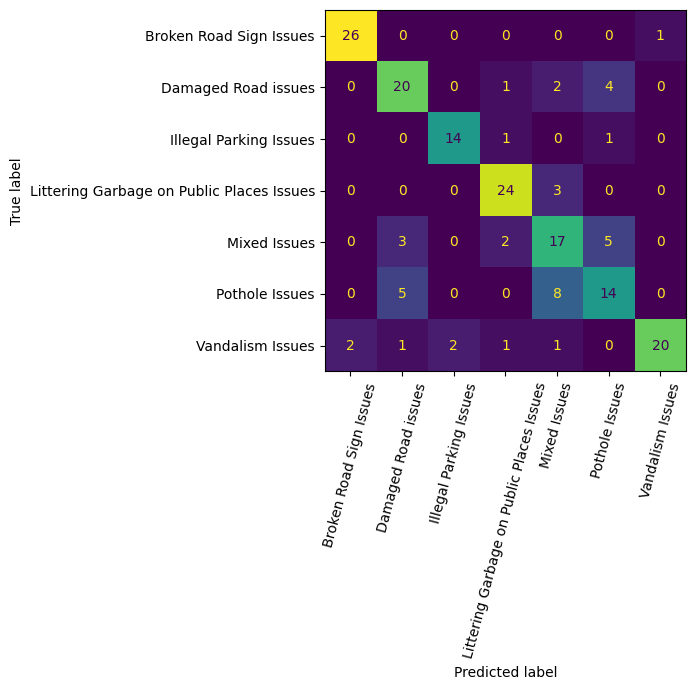

In [15]:
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
val_logits, val_y = get_outputs(val_loader)
def nll_temp(logT):
    lg = val_logits/np.exp(logT)
    return float(np.mean(logsumexp(lg, axis = 1)-lg[np.arange(len(val_y)), val_y]))
result = minimize_scalar(nll_temp, bounds = (-2, 2), method = 'bounded')
TEMPERATURE = float(np.exp(result.x))
test_logits, test_y = get_outputs(test_loader)
pred = test_logits.argmax(axis = 1)
print('Temperature (val):', TEMPERATURE)
print('Test accuracy', accuracy_score(test_y, pred),'Macro-F1', f1_score(test_y, pred, average = 'macro', zero_division = 0))
print(classification_report(test_y, pred, labels = list(range(len(names))), target_names = names, zero_division = 0))
pd.DataFrame(classification_report(test_y, pred, labels = list(range(len(names))), target_names = names, zero_division = 0, output_dict = True)).T.to_csv('classification_report.csv')
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize = (9, 7))
ConfusionMatrixDisplay(confusion_matrix(test_y, pred, labels = list(range(len(names)))), display_labels = names).plot(ax = ax, xticks_rotation = 75, colorbar = False)
fig.tight_layout()
fig.savefig('confusion_matrix.png', dpi = 145)
plt.show()

## 06に渡す学習済み重みと未使用評価画像

学習重みと**testセットだけから選んだ画像**6枚をZIPにまとめます。画像は「道路側の独立した仮想カメラから届く撮影データ」として扱い、Genesisレンダリング画像とは区別します。

In [16]:
import zipfile
import json
import shutil
from pathlib import Path
AS = Path('road_ml_assets')
AS.mkdir(exist_ok = True)
checkpoint={
 'state_dict':{k:v.detach().cpu() for k, v in model.state_dict().items()},
 'labels':names,'temperature':TEMPERATURE,'source':REPO_ID,'revision':REVISION,
 'model_architecture':'torchvision.mobilenet_v3_small','seed':SEED,
 'train_size':len(train_idx),'test_size':len(test_idx)}
torch.save(checkpoint, AS/'road_mobilenetv3.pt')
# 6 distinct labels from held-out set. No test image is used for optimization.
stations = list('ABCDEF')
entries = []
for station, c in zip(stations, range(6)):
    eligible = [int(i) for i in test_idx if int(y[int(i)]) == c]
    assert eligible,f'No heldout example for {names[c]}'
    row = subset[eligible[0]]
    fn=f'inspection_{station}.jpg'
    row['image'].convert('RGB').save(AS/fn, quality = 90)
    entries.append({'station':station,'image':fn,'label':names[c],'dataset_row':selected[eligible[0]]})
(AS/'station_manifest.json').write_text(json.dumps(entries, ensure_ascii = False, indent = 2), encoding = 'utf8')
(AS/'model_card.json').write_text(json.dumps({'model':'MobileNetV3-Small','data':REPO_ID,'revision':REVISION,
    'dataset_license':'CC0-1.0 (dataset card; source assets may have differing rights)',
    'ai_task':'issue category classification','risk_policy':'hand-defined, NOT learned severity',
    'validation_macro_f1':history[-1]['val_macro_f1'],'test_macro_f1':float(f1_score(test_y, pred, average = 'macro', zero_division = 0))}, indent = 2), encoding = 'utf8')
with zipfile.ZipFile('road_ml_assets.zip','w', compression = zipfile.ZIP_DEFLATED) as z:
    for file in sorted(AS.iterdir()):
        z.write(file, arcname = file.name)
print('Created road_ml_assets.zip; no HFH_READ saved')
from google.colab import files
files.download('road_ml_assets.zip')

Created road_ml_assets.zip; no HFH_READ saved


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>